In [1]:
%pylab inline

import os
from astropy.table import Table, vstack
import astropy.io.fits as pyfits

import matplotlib
import matplotlib.patches as mpatches

from lsst.daf.persistence import Butler
#butler16 = Butler('./homeDir/data/hsc_ssp/dr1/s16a/data/s16a_wide2/')
#butler18 = Butler('./homeDir/data/hsc_ssp/dr2/s18a/data/test/s18a_wide_revpsf/')
butler19 = Butler('./homeDir/data/hsc_ssp/dr3/s19a/data/s19a_wide/')
skymap  =    butler19.get('deepCoadd_skyMap')

import lsst.afw.table as afwTable
import lsst.afw.image as afwImage
import lsst.afw.display as afwDisplay
#import lsst.afw.geom as afwGeom
import lsst.geom as afwGeom
from lsst.meas.base.noiseReplacer import NoiseReplacerConfig,NoiseReplacer
import lsst.analysis.deblender as deblender

import astropy.io.ascii as ascii

Populating the interactive namespace from numpy and matplotlib


Config override file '?' appears to use 'root' instead of 'config'; trying with 'root'


# 1 CAMIRA


Text(0.5, 0, 'ncor')

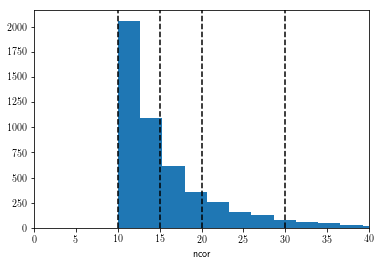

In [149]:
a=ascii.read('wrkDir/database/CAMIRA_S16A.csv')
hist,grid,fig=plt.hist(a['N_cor'],40)
plt.xlim(0,40)
cutlist=[10,15,20,30,80]
for ic in cutlist:
    axvline(ic,c='black',ls='--')
plt.xlabel('ncor')

Text(0.5, 0, 'R (arcmin)')

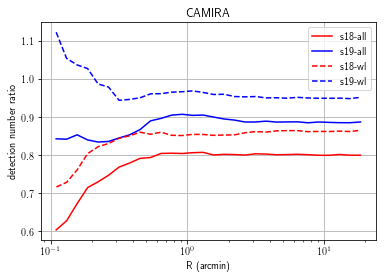

In [15]:
d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',label='s19-all')
d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',ls='--',label='s19-wl')
plt.legend()
plt.grid()
plt.title('CAMIRA')
plt.xlabel('R (arcmin)')
plt.ylabel('detection number ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

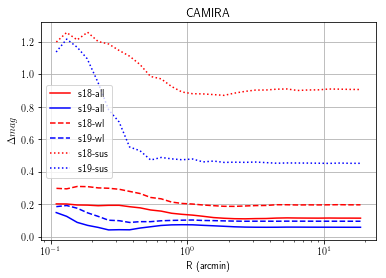

In [16]:
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['kappa'],c='blue',label='s19-all')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls='--',label='s19-wl')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-CAMIRA-mag-ncor-all-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-CAMIRA-mag-ncor-all-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls=':',label='s18-sus')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls=':',label='s19-sus')
plt.title('CAMIRA')
plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.grid()
plt.legend()

Text(0.5, 0, 'R (arcmin)')

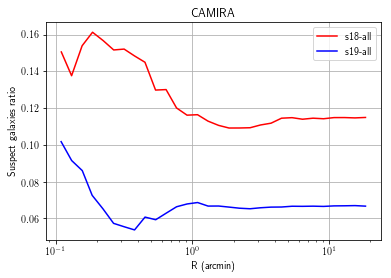

In [17]:
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-CAMIRA-susRatio-ncor-all-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-CAMIRA-susRatio-ncor-all-s19.csv')
d18wl=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-susRatio-ncor-all-s18.csv')
d19wl=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-susRatio-ncor-all-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d18wl['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d19wl['npairs'],c='blue',label='s19-all')

plt.legend()
plt.grid()
plt.title('CAMIRA')
plt.xlabel('R (arcmin)')
plt.ylabel('Suspect galaxies ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

Text(0.5, 0, 'R (arcmin)')

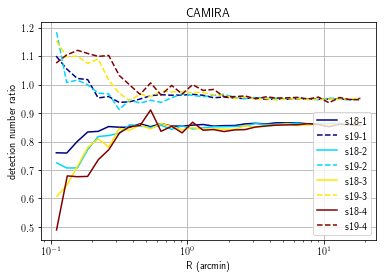

In [26]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-ncor-g%s-s16.csv' %ig)
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-ncor-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-ncor-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c=colors[ig],label='s18-%s' %(ig+1),ls='-')
    plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c=colors[ig],label='s19-%s' %(ig+1),ls='--')

plt.legend(loc='lower right')
plt.grid()
plt.title('CAMIRA')
plt.xlabel('R (arcmin)')
plt.ylabel('detection number ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

# GAIA

Text(0.5, 0, 'mag')

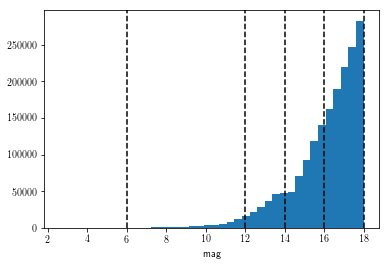

In [21]:
import astropy.io.fits as pyfits
a=pyfits.getdata('wrkDir/database/GAIA_Stars.fits',ext=1)
hist,grid,fig=plt.hist(a['G_Gaia'],40)
cutlist=[6,12,14,16,18]
for ic in cutlist:
    axvline(ic,c='black',ls='--')
plt.xlabel('mag')

Text(0.5, 0, 'R (arcmin)')

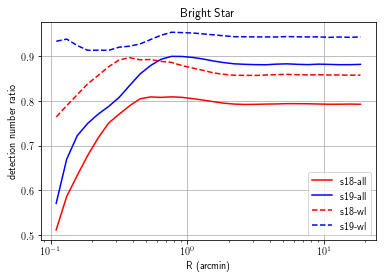

In [18]:
d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',label='s19-all')

d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',ls='--',label='s19-wl')
plt.legend()
plt.grid()
plt.title('Bright Star')
plt.xlabel('R (arcmin)')
plt.ylabel('detection number ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

Text(0.5, 0, 'R (arcmin)')

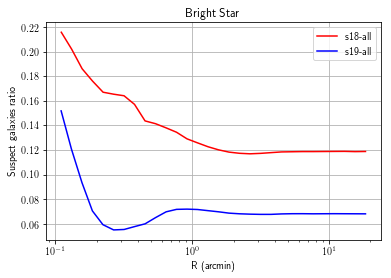

In [19]:
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-star-susRatio-mag-all-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-star-susRatio-mag-all-s19.csv')
d18wl=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-susRatio-mag-all-s18.csv')
d19wl=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-susRatio-mag-all-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d18wl['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d19wl['npairs'],c='blue',label='s19-all')

plt.legend()
plt.grid()
plt.title('Bright Star')
plt.xlabel('R (arcmin)')
plt.ylabel('Suspect galaxies ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

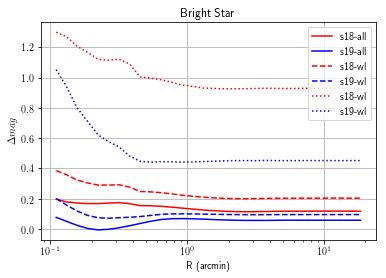

In [20]:
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['kappa'],c='blue',label='s19-all')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls='--',label='s19-wl')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-star-mag-mag-all-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-star-mag-mag-all-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls=':',label='s18-wl')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls=':',label='s19-wl')
plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('Bright Star')
plt.grid()
plt.legend()

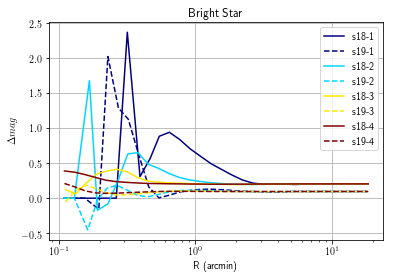

In [22]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-mag-mag-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-mag-mag-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig+1), color=colors[ig], ls='-')
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig+1), color=colors[ig], ls='--')


plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('Bright Star')
plt.grid()
plt.legend()

Text(0.5, 0, 'R (arcmin)')

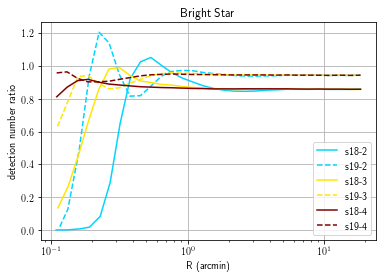

In [23]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(1,4):
    d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-mag-g%s-s16.csv' %ig)
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-mag-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-mag-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c=colors[ig],label='s18-%s' %(ig+1),ls='-')
    plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c=colors[ig],label='s19-%s' %(ig+1),ls='--')

plt.legend()
plt.grid()
plt.title('Bright Star')
plt.xlabel('R (arcmin)')
plt.ylabel('detection number ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

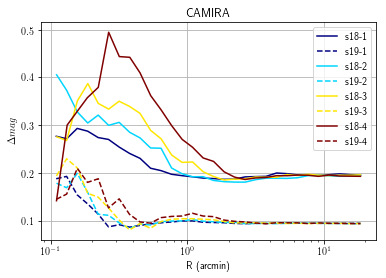

In [25]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-ncor-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-ncor-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig+1), color=colors[ig], ls='-')
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig+1), color=colors[ig], ls='--')

plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('CAMIRA')

plt.grid()
plt.legend()

# ICG

Text(0.5, 0, 'mag')

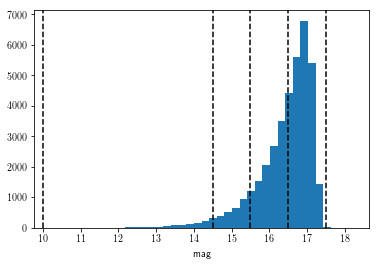

In [3]:
import astropy.io.fits as pyfits
a=ascii.read('wrkDir/database/Wang_S16A.csv')
hist,grid,fig=plt.hist(a['imag_model'],40)
cutlist=[10,14.5,15.5,16.5,17.5]
for ic in cutlist:
    axvline(ic,c='black',ls='--')
plt.xlabel('mag')

In [6]:
for i in range(len(cutlist)-1):
    mask = (a['imag_model']>cutlist[i])&(a['imag_model']<cutlist[i+1])
    num=np.sum(mask)
    print(num,num/137/3600.)

1027 0.0020823195458231952
3156 0.006399026763990267
12073 0.024478913219789133
22120 0.04484995944849959


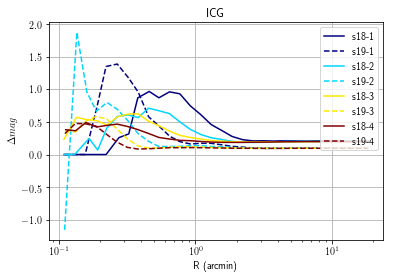

In [14]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-Wang-mag-mag-g%s-s18.csv' %ig)
    plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig+1), color=colors[ig], ls='-')
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-Wang-mag-mag-g%s-s19.csv' %ig)
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig+1), color=colors[ig], ls='--')

plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('ICG')

plt.grid()
plt.legend(loc='upper right')

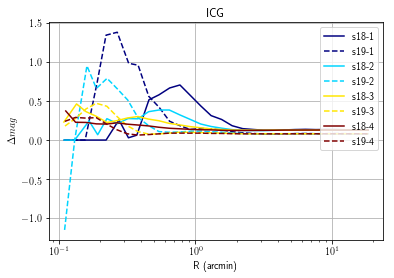

In [15]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl2-Wang-mag-mag-g%s-s18.csv' %ig)
    plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig+1), color=colors[ig], ls='-')
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl2-Wang-mag-mag-g%s-s19.csv' %ig)
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig+1), color=colors[ig], ls='--')

plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('ICG')

plt.grid()
plt.legend(loc='upper right')

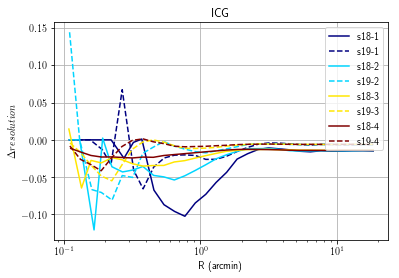

In [16]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl2-Wang-res-mag-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl2-Wang-res-mag-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig+1), color=colors[ig], ls='-')
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig+1), color=colors[ig], ls='--')

plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta resolution$')
plt.xscale('log')
plt.title('ICG')

plt.grid()
plt.legend(loc='upper right')

In [8]:
# Preparing data
catNei=Table.read('./wrkDir/database/compare/ICG-neighbour-SDSS-undetect.csv')
catCen=Table.read('./wrkDir/database/compare/ICG_MW-central-20200316.csv')
if False:
    cids=np.unique(catNei['central_id'])
    catCen=catCen[cids-1]
    catCen['central_id']=cids
    catCen.write('./wrkDir/database/compare/ICG_MW-central-20200316.csv')

if False:
    catCen['tract']=None
    catCen['patch']=None
    for ss in catCen:
        centCoord=afwGeom.SpherePoint(afwGeom.Angle(ss['ra'],afwGeom.degrees),afwGeom.Angle(ss['dec'],afwGeom.degrees))
        TPinfo=skymap.findClosestTractPatchList([centCoord])[0]
        ss['tract']=TPinfo[0].getId()
        ss['patch']='%d,%d' %TPinfo[1][0].getIndex()
    catCen.write('./wrkDir/database/compare/ICG_MW-central-20200316.csv')
        
tractlist=[15827,15829,15831,15833,16006,16008,16010,8279,8281,8283,8285,8521,8523,8525,8762,8764,8766,8768,9005,9007,9009]
catCen=catCen[np.in1d(catCen['tract'],tractlist)]

isRed=catCen['g_m_r']>0.065*catCen['log_M']+0.1
catRed=catCen[isRed]
catBlue=catCen[~isRed]
#maxIDs=np.argsort(np.bincount(catWT['central_id']))[:-20:-1]
catRed=catRed[np.argsort(catRed['log_M'])[-30:]]
catBlue=catBlue[np.argsort(catBlue['log_M'])[-30:]]

In [10]:
#Show all Galaxies
def findInAperture(centList,radius,cat):
    """Return the objects within Aperture"""
    oneObjCatalog = afwTable.SourceCatalog(cat.getSchema())
    centroidName = cat.table.getCentroidDefinition()
    oneObjCatalog.table.defineCentroid(centroidName)

    for cent in centList:
        x, y = cent.getX(), cent.getY()
        s = oneObjCatalog.addNew()
        s.set("%s_x" % centroidName, x)
        s.set("%s_y" % centroidName, y)

    return afwTable.matchXy(cat, oneObjCatalog, radius)

afwDisplay.setDefaultBackend('matplotlib')
plt.rcParams['figure.figsize'] = (15, 15)

showR=300
for igal in range(6):
    ssCen=catRed[igal]
    colorname='Red'
    catUnMat=catNei[catNei['central_id']==ssCen['central_id']]

    dataId = {'filter': 'HSC-R', 'tract': ssCen['tract'], 'patch': ssCen['patch']}
    exp19 = butler19.get('deepCoadd_calexp', **dataId)
    src19=butler19.get('deepCoadd_meas',**dataId)

    centCoord=afwGeom.SpherePoint(afwGeom.Angle(ssCen['ra'],afwGeom.degrees),afwGeom.Angle(ssCen['dec'],afwGeom.degrees))
    wcs=exp19.getWcs()
    centPoint=afwGeom.Point2I(wcs.skyToPixel(centCoord))

    extU=afwGeom.Extent2I(showR,showR)
    boxU=afwGeom.Box2I(centPoint-extU,2*extU)
    boxU.clip(exp19.getBBox())
    expShow=exp19[boxU]
    display1 = afwDisplay.getDisplay(frame=1)
    display1.setMaskTransparency(100)
    #display1.scale("Asinh", "zscale")
    display1.scale("asinh", "zscale")
    display1.mtv(expShow,title='ICG %d pix' %(showR))

    nameNchild = "deblend_nChild"
    mIdList=[]
    matched=findInAperture([centPoint],showR,src19)

    with display1.Buffering(): 
        for mm in matched:
            ssShow=mm[0]
            if ssShow[nameNchild]==0:
                label='+'
                display1.dot(label,ssShow.getX(),ssShow.getY(), size=3, ctype=afwDisplay.GREEN) 
                mIdList.append(ssShow.getId())
        for ssShow in catUnMat:
            raShow=ssShow['satellite_ra']
            decShow=ssShow['satellite_dec']
            cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
            pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
            #print(pShow-centPoint)
            label='o'
            display1.dot(label,pShow.getX(),pShow.getY(), size=3, ctype=afwDisplay.RED) 

    display1.savefig('./wrkDir/exfaGalAll/plot-brightObj/S19-ICG-%s-ID-%d.png' %(colorname,ssCen['central_id']))

    # Show Interested Galaxies
    mos=afwDisplay.utils.Mosaic()
    noiConfig   =   NoiseReplacerConfig()
    fp19  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
                  for measRecord in src19}
    nrper19=  NoiseReplacer(noiConfig, exp19, fp19)

    display2 = afwDisplay.getDisplay(frame=2)
    display2.setMaskTransparency(90)
    #display2.scale("Asinh", "zscale")
    display2.scale("asinh", "zscale")
        
    for ssShow in catUnMat:
        raShow=ssShow['satellite_ra']
        decShow=ssShow['satellite_dec']
        cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
        pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
        matched=findInAperture([pShow],4,src19)
        for mm in matched:
            ss=mm[0]
            if ss[nameNchild]==0:
                cc=afwGeom.Point2I(ss.getCentroid())
                dis=cc-centPoint
                label='%d,%d' %(dis.getX(),dis.getY())
                boxU.clip(exp19.getBBox())
                extU=afwGeom.Extent2I(32,32)
                boxU=afwGeom.Box2I(cc-extU,2*extU)
                nrper19.insertSource(ss.getId())
                imgShow=afwImage.MaskedImageF(boxU)
                imgShow.getImage().getArray()[:,:]=exp19.getImage()[boxU].getArray()[:,:]
                mos.append(imgShow,label=label)
                del imgShow
                nrper19.removeSource(ss.getId())

    mos.makeMosaic(display=display2,title='UnMatched')
    display2.savefig('./wrkDir/exfaGalAll/plot-brightObj/S19-ICG-%s-ID-%d-unMat.png' %(colorname,ssCen['central_id']))

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:5: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
  """
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:5: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
  """
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:5: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
  """
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:5: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().